In [956]:
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [957]:
torch.manual_seed(42)

In [958]:
df = pd.read_csv("08-seismic_activity_svm.csv")

In [959]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [960]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [961]:
df.describe()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
count,400.000000,4.000000e+02,400.000000
mean,0.000000,8.881784e-18,0.500000
std,7.719350,1.751650e+00,0.500626
min,-9.999954,-3.000000e+00,0.000000
25%,-6.134779,-1.500000e+00,0.000000
50%,0.000000,0.000000e+00,0.500000
75%,6.134779,1.500000e+00,1.000000
max,9.999954,3.000000e+00,1.000000


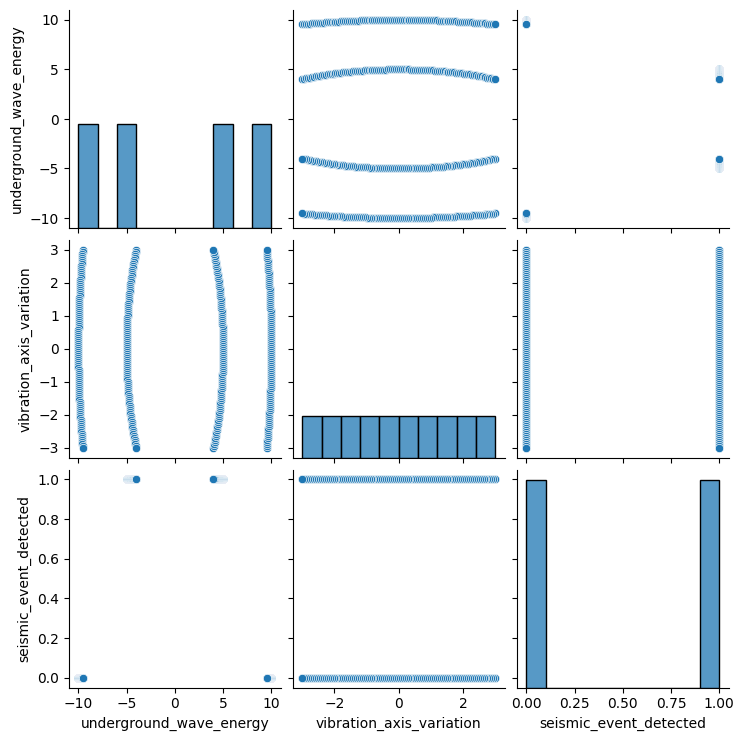

In [962]:
sns.pairplot(df)
plt.show()

In [963]:
from scipy.stats import skew

In [964]:
df.apply(skew, axis=0)

,0
underground_wave_energy,0.000000e+00
vibration_axis_variation,-1.327025e-17
seismic_event_detected,0.000000e+00


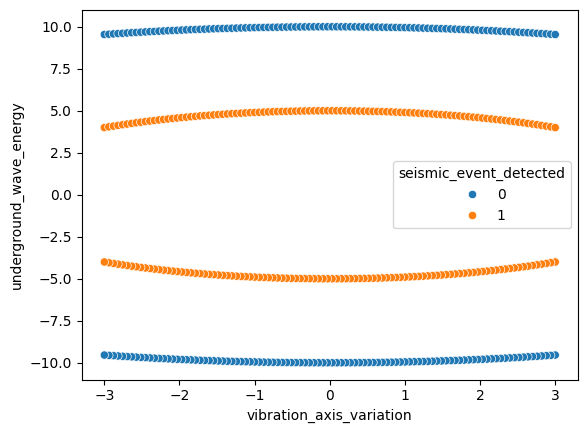

In [965]:
sns.scatterplot(data=df, x="vibration_axis_variation", y="underground_wave_energy", hue="seismic_event_detected")
plt.show()

In [966]:
from sklearn.model_selection import train_test_split

X = df.drop("seismic_event_detected", axis=1).values
y = df["seismic_event_detected"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [967]:
def calculate_accuracy(y_test, y_pred):
  correct = torch.eq(y_test, y_pred).sum().item()
  accuracy = (correct/len(y_test)) * 100
  return accuracy

In [968]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

In [969]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

(torch.Size([320, 2]),
 torch.Size([80, 2]),
 torch.Size([320, 1]),
 torch.Size([80, 1]))

In [970]:
from torch import nn

In [971]:
class LinearModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2, out_features=2)
    self.layer_2 = nn.Linear(in_features=2, out_features=1)

  def forward(self, x: torch.tensor) -> torch.tensor:
    return self.layer_2(self.layer_1(x))


In [972]:
model = LinearModel()

In [973]:
list(model.parameters())

[Parameter containing:
 tensor([[ 0.5406,  0.5869],
         [-0.1657,  0.6496]], requires_grad=True),
 Parameter containing:
 tensor([-0.1549,  0.1427], requires_grad=True),
 Parameter containing:
 tensor([[-0.3443,  0.4153]], requires_grad=True),
 Parameter containing:
 tensor([0.6233], requires_grad=True)]

In [974]:
model.state_dict()

OrderedDict([('layer_1.weight',
              tensor([[ 0.5406,  0.5869],
                      [-0.1657,  0.6496]])),
             ('layer_1.bias', tensor([-0.1549,  0.1427])),
             ('layer_2.weight', tensor([[-0.3443,  0.4153]])),
             ('layer_2.bias', tensor([0.6233]))])

In [975]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.01)


In [976]:
epochs = 250

for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  y_pred = torch.sigmoid(y_logits)
  loss = loss_fn(y_pred, y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


  model.eval()
  with torch.inference_mode():
    test_pred_logits = model(X_test)
    test_pred = torch.sigmoid(test_pred_logits)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 5 == 0:
    print(f"epoch: {epoch} | train loss: {loss} | test loss: {test_loss}")


epoch: 0 | train loss: 1.1538172960281372 | test loss: 1.0101193189620972
epoch: 5 | train loss: 0.9807661771774292 | test loss: 0.8947064280509949
epoch: 10 | train loss: 0.883787989616394 | test loss: 0.8383170962333679
epoch: 15 | train loss: 0.8281283378601074 | test loss: 0.8117712140083313
epoch: 20 | train loss: 0.7950522303581238 | test loss: 0.8000496625900269
epoch: 25 | train loss: 0.7746867537498474 | test loss: 0.7956267595291138
epoch: 30 | train loss: 0.761709988117218 | test loss: 0.7946873903274536
epoch: 35 | train loss: 0.7531485557556152 | test loss: 0.7952672243118286
epoch: 40 | train loss: 0.7472849488258362 | test loss: 0.7963536977767944
epoch: 45 | train loss: 0.743099570274353 | test loss: 0.7974379658699036
epoch: 50 | train loss: 0.7399749755859375 | test loss: 0.7982820868492126
epoch: 55 | train loss: 0.7375310063362122 | test loss: 0.7987940311431885
epoch: 60 | train loss: 0.7355313897132874 | test loss: 0.7989582419395447
epoch: 65 | train loss: 0.7338

In [977]:
y_pred_linear = torch.round(test_pred)
y_pred_linear = y_pred_linear.squeeze(1)

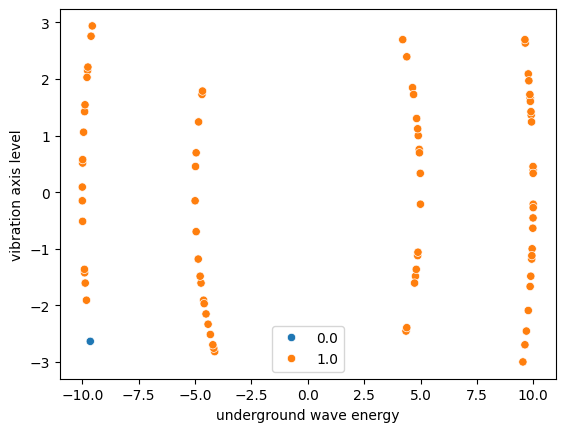

In [978]:
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_pred_linear)
plt.xlabel("underground wave energy")
plt.ylabel("vibration axis level")
plt.legend()
plt.show()

In [979]:
y_pred_linear_acc_score = calculate_accuracy(y_test=y_test, y_pred=torch.round(test_pred))

In [980]:
from torch.nn import ReLU

In [981]:
relu = ReLU()

In [982]:
relu(torch.randn(1,2,3))

tensor([[[1.5231, 0.6647, 0.0000],
         [0.0000, 0.0000, 0.0000]]])

In [983]:
import torch.nn.functional as F

In [984]:
class NonLinearModel(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer1 = nn.Linear(in_features=2, out_features=3)
    self.layer2 = nn.Linear(in_features=3, out_features=1)

  def forward(self, x: torch.tensor) -> torch.tensor:
    x = F.relu(self.layer1(x))
    x = self.layer2(x)

    return x


In [985]:
model = NonLinearModel()

In [986]:
model.parameters()

<generator object Module.parameters at 0x7ac5714c4120>

In [987]:
model.state_dict()

OrderedDict([('layer1.weight',
              tensor([[-0.0829, -0.2872],
                      [ 0.4691, -0.5582],
                      [-0.3260, -0.1997]])),
             ('layer1.bias', tensor([-0.4252,  0.0667, -0.6984])),
             ('layer2.weight', tensor([[ 0.5214, -0.4904,  0.4457]])),
             ('layer2.bias', tensor([0.0961]))])

In [988]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)

In [989]:
epochs = 300

for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  loss = loss_fn(torch.sigmoid(y_logits), y_train)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model.eval()
  with torch.inference_mode():
    test_logits = model(X_test)
    test_pred = torch.sigmoid(test_logits)
    test_loss = loss_fn(test_pred, y_test)


  if epoch % 5 == 0:
    print(f"epoch: {epoch} | train loss: {loss} | test loss: {test_loss}")

epoch: 0 | train loss: 0.9259904623031616 | test loss: 0.7000112533569336
epoch: 5 | train loss: 0.6765912175178528 | test loss: 0.6194822192192078
epoch: 10 | train loss: 0.6606059670448303 | test loss: 0.6177600622177124
epoch: 15 | train loss: 0.6570608019828796 | test loss: 0.6166181564331055
epoch: 20 | train loss: 0.6546515226364136 | test loss: 0.6151115298271179
epoch: 25 | train loss: 0.6526638269424438 | test loss: 0.6135822534561157
epoch: 30 | train loss: 0.6508543491363525 | test loss: 0.6117467880249023
epoch: 35 | train loss: 0.6492040753364563 | test loss: 0.6096166968345642
epoch: 40 | train loss: 0.6476340889930725 | test loss: 0.6074431538581848
epoch: 45 | train loss: 0.6461294293403625 | test loss: 0.6054559946060181
epoch: 50 | train loss: 0.6446824073791504 | test loss: 0.6033311486244202
epoch: 55 | train loss: 0.6432836055755615 | test loss: 0.6015969514846802
epoch: 60 | train loss: 0.6419280171394348 | test loss: 0.5998010635375977
epoch: 65 | train loss: 0.6

In [990]:
test_pred

tensor([[0.7070],
        [0.5318],
        [0.1999],
        [0.7023],
        [0.1305],
        [0.1357],
        [0.6065],
        [0.1300],
        [0.5241],
        [0.6065],
        [0.2598],
        [0.6065],
        [0.1625],
        [0.1450],
        [0.6065],
        [0.1833],
        [0.5118],
        [0.6985],
        [0.6147],
        [0.7933],
        [0.1408],
        [0.2424],
        [0.8445],
        [0.5177],
        [0.2894],
        [0.8797],
        [0.6065],
        [0.6375],
        [0.5305],
        [0.6065],
        [0.8732],
        [0.6122],
        [0.5322],
        [0.1612],
        [0.6111],
        [0.6065],
        [0.6065],
        [0.6065],
        [0.6065],
        [0.6065],
        [0.7536],
        [0.1638],
        [0.1416],
        [0.2171],
        [0.1370],
        [0.7639],
        [0.6065],
        [0.6065],
        [0.2243],
        [0.6065],
        [0.1768],
        [0.6065],
        [0.6065],
        [0.1469],
        [0.6749],
        [0

In [991]:
y_pred_relu_acc_score = calculate_accuracy(y_test=y_test, y_pred=torch.round(test_pred))

In [992]:
y_pred_relu = torch.round(test_pred)

In [993]:
y_pred_relu = y_pred_relu.squeeze(1)

In [994]:
type(y_pred_relu)

torch.Tensor

In [995]:
type(X_test)

torch.Tensor

In [996]:
X_test.shape

torch.Size([80, 2])

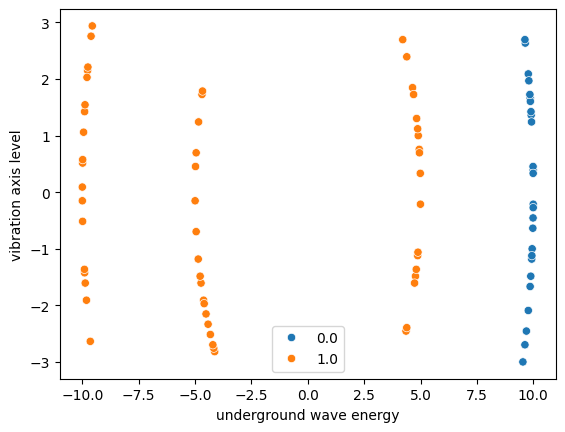

In [997]:
sns.scatterplot(x=X_test[:, 0], y=X_test[:, 1], hue=y_pred_relu)
plt.xlabel("underground wave energy")
plt.ylabel("vibration axis level")
plt.legend()
plt.show()

In [998]:
#report

print(f"Model Accuracy Score without ReLU: {y_pred_linear_acc_score}\n")
print(f"Model Accuracy Score with ReLU: {y_pred_relu_acc_score}")


Model Accuracy Score without ReLU: 46.25

Model Accuracy Score with ReLU: 77.5
